# Ejercicio 1 Análisis de sets LEGO y agrupamiento

Trabajo práctico 1 de Ciencia de Datos. Grupo 14.

**Objetivo:** integrar datos públicos de Rebrickable y describir perfiles de construcción. La unidad de análisis es un set, no una fila de inventario. Estudiamos sets publicados entre 2000 y 2025, con al menos 20 piezas declaradas e inventario de piezas disponible. El corte evita comparar años incompletos y los sets muy pequeños o promocionales; las conclusiones no describen todo el catálogo histórico.

Preguntas de investigación:

1. ¿Cómo cambia el tamaño de los sets entre años y hasta qué punto difiere entre familias temáticas?
2. ¿Qué relación hay entre tamaño y variedad de colores, y cómo cambia entre temas?
3. ¿Los sets con mayor proporción de piezas Technic repiten más sus tipos de piezas?

Hipótesis iniciales, no resultados: los temas pueden tener composiciones y tamaños distintos; una mayor cantidad de piezas no implica proporcionalmente más colores; la composición técnica puede asociarse con repetición. No interpretaremos asociaciones como causalidad.

Los cuatro archivos obligatorios se complementan con **parts** y **colors**, que permiten medir diversidad de piezas y transparencias, y **part_categories**, que permite identificar piezas Technic. Fuentes: https://rebrickable.com/downloads/ y los enlaces y hashes de `fuentes_rebrickable.json`.

## Integrantes

- Calandria, Alén Santiago (padrón: 112103).
- Szinvelski, Sol Yohara (padrón: 112985).
- Garay Alvarado, Gustavo Alfredo (padrón: intercambio-02).
- Sosa, Matias (padrón: 113352).
- Fontanals Layos, Oriol (padrón: intercambio-03).

In [1]:
from pathlib import Path
import json,hashlib,platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn,joblib
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score,silhouette_samples,adjusted_rand_score
from sklearn.decomposition import PCA
ROOT=Path.cwd()
if not (ROOT/'datos/rebrickable').exists() and (ROOT.parent/'datos/rebrickable').exists(): ROOT=ROOT.parent
DATA=ROOT/'datos/rebrickable';OUT=ROOT/'resultados/ej1';OUT.mkdir(parents=True,exist_ok=True)
for folder in ['figuras','modelos','datos/procesados']:(ROOT/folder).mkdir(parents=True,exist_ok=True)
SEED=42
plt.rcParams.update({'font.size':10,'figure.dpi':110})
tables={name:pd.read_csv(DATA/f'{name}.csv.gz') for name in ['sets','themes','inventories','inventory_parts','parts','colors','part_categories']}
inventory=pd.DataFrame([dict(archivo=n,filas=len(t),columnas=t.shape[1],faltantes=int(t.isna().sum().sum()),duplicadas=int(t.duplicated().sum())) for n,t in tables.items()])
display(inventory);inventory.to_csv(OUT/'inventario_fuentes.csv',index=False)
sets,themes,inventories,ip,parts,colors,categories=[tables[n] for n in ['sets','themes','inventories','inventory_parts','parts','colors','part_categories']]
for df,key in [(sets,'set_num'),(themes,'id'),(inventories,'id'),(parts,'part_num'),(colors,'id'),(categories,'id')]:assert df[key].is_unique
print('Versiones:',platform.python_version(),pd.__version__,sklearn.__version__)
def savefig(name):
    plt.tight_layout();plt.savefig(ROOT/'figuras'/f'ej1_{name}.png',dpi=150,bbox_inches='tight');plt.show()

Versiones: 3.12.14 3.0.1 1.9.0


,archivo,filas,columnas,faltantes,duplicadas
0,sets,28492,6,0,0
1,themes,496,3,150,0
2,inventories,47733,3,0,0
3,inventory_parts,1566159,6,6920,0
4,parts,64880,4,0,0
5,colors,275,8,4,0
6,part_categories,76,2,0,0


## Integración y control de calidad

Elegimos la versión de inventario de mayor número para cada set. No sumamos versiones alternativas. La unión con sets es uno a uno y las dimensiones de piezas, colores y categorías se verifican como muchos a uno. Quitamos repuestos (`is_spare`) y colores sin definición utilizable para las métricas de composición. Los registros excluidos quedan contados.

La cantidad de piezas del inventario no siempre coincide con `num_parts`: puede haber minifiguras, subinventarios o diferencias de cobertura. Conservamos ambas medidas y mostramos la discrepancia; no corregimos el catálogo sin evidencia.

In [2]:
parent=themes.set_index('id')['parent_id'].to_dict();tnames=themes.set_index('id')['name'].to_dict()
def root_theme(t):
    seen=set()
    while pd.notna(parent.get(t)):
        if t in seen: raise ValueError('Ciclo en jerarquía temática')
        seen.add(t);t=int(parent[t])
    return tnames.get(t,'Tema no identificado')
sets=sets.copy();sets['theme_root']=sets['theme_id'].map(root_theme)
selected=sets.loc[sets['year'].between(2000,2025)&sets['num_parts'].ge(20)].copy()
latest=inventories.sort_values(['set_num','version','id']).drop_duplicates('set_num',keep='last')
selected=selected.merge(latest[['set_num','id','version']],on='set_num',how='left',validate='one_to_one').rename(columns={'id':'inventory_id'})
raw_rows=len(ip)
p=ip.loc[ip['inventory_id'].isin(selected['inventory_id'])&~ip['is_spare'].astype(str).str.lower().isin(['t','true','1'])].copy()
before=len(p);p=p.drop_duplicates(subset=['inventory_id','part_num','color_id','quantity','is_spare'])
duplicate_rows_removed=before-len(p)
p=p.merge(parts[['part_num','part_cat_id']],on='part_num',how='left',validate='many_to_one')
p=p.merge(categories.rename(columns={'id':'part_cat_id','name':'category'}),on='part_cat_id',how='left',validate='many_to_one')
p=p.merge(colors[['id','name','is_trans']].rename(columns={'id':'color_id','name':'color_name'}),on='color_id',how='left',validate='many_to_one')
missing=p[['part_cat_id','category','color_name','is_trans']].isna().sum().to_dict()
invalid=(p['quantity']<=0)|p['quantity'].isna()|p['color_name'].isna()|p['color_id'].lt(0)|p['category'].isna()
excluded_rows=int(invalid.sum());p=p.loc[~invalid].copy()
p['trans_qty']=p['quantity']*p['is_trans'].astype(str).str.lower().isin(['t','true','1'])
p['technic_qty']=p['quantity']*p['category'].str.startswith('Technic')
agg=p.groupby('inventory_id').agg(inventory_quantity=('quantity','sum'),unique_parts=('part_num','nunique'),
    n_colors=('color_id','nunique'),n_categories=('part_cat_id','nunique'),trans_qty=('trans_qty','sum'),technic_qty=('technic_qty','sum'))
analytical=selected.merge(agg,on='inventory_id',how='left',validate='one_to_one')
without_inventory=int(analytical['inventory_quantity'].isna().sum())
analytical=analytical.loc[analytical['inventory_quantity'].gt(0)].copy()
analytical['unique_part_ratio']=analytical['unique_parts']/analytical['inventory_quantity']
analytical['transparent_ratio']=analytical['trans_qty']/analytical['inventory_quantity']
analytical['technic_ratio']=analytical['technic_qty']/analytical['inventory_quantity']
analytical['inventory_gap']=analytical['inventory_quantity']-analytical['num_parts']
assert analytical['set_num'].is_unique
assert analytical[['unique_part_ratio','transparent_ratio','technic_ratio']].ge(0).all().all()
assert analytical[['unique_part_ratio','transparent_ratio','technic_ratio']].le(1).all().all()
quality=dict(source_sets=len(sets),eligible_sets=len(selected),analytical_sets=len(analytical),no_valid_inventory=without_inventory,
    excluded_inventory_rows=excluded_rows,duplicate_inventory_rows_removed=duplicate_rows_removed,join_missing=missing,
    mismatching_piece_counts=int(analytical['inventory_gap'].ne(0).sum()))
print(quality);display(analytical[['year','num_parts','inventory_quantity','n_colors','unique_part_ratio']].describe())
analytical.to_csv(ROOT/'datos/procesados/lego_sets_analitico.csv',index=False)

{'source_sets': 28492, 'eligible_sets': 11186, 'analytical_sets': 11158, 'no_valid_inventory': 28, 'excluded_inventory_rows': 2, 'duplicate_inventory_rows_removed': 0, 'join_missing': {'part_cat_id': 0, 'category': 0, 'color_name': 0, 'is_trans': 0}, 'mismatching_piece_counts': 5535}


,year,num_parts,inventory_quantity,n_colors,unique_part_ratio
count,11158.000000,11158.000000,11158.000000,11158.000000,11158.000000
mean,2014.873275,338.904553,331.152626,13.628070,0.366324
std,7.345961,611.715519,605.797536,8.204392,0.198570
min,2000.000000,20.000000,1.000000,1.000000,0.000666
25%,2009.000000,49.000000,47.000000,8.000000,0.218450
50%,2016.000000,132.000000,127.000000,12.000000,0.348837
75%,2021.000000,370.750000,357.000000,18.000000,0.500000
max,2025.000000,11695.000000,11695.000000,57.000000,1.000000


## Faltantes y valores atípicos

No imputamos inventarios ausentes como cero piezas. Los sets sin inventario válido se excluyen de este análisis y se cuentan. Un padre ausente en themes puede ser una raíz legítima de la jerarquía. Las variables derivadas de composición requieren dimensiones conocidas; los registros que no las tienen se excluyen y se documentan.

Detectamos extremos con IQR, pero conservamos sets grandes reales. Para agrupamiento aplicamos log1p al tamaño y cantidad de colores, seguido de estandarización. Así reducimos asimetrías sin declarar que los sets grandes sean errores.

,variable,limite_inferior,limite_superior,cantidad
0,num_parts,-433.625000,853.375000,1050
1,inventory_quantity,-418.000000,822.000000,1075
2,n_colors,-7.000000,33.000000,297
3,unique_part_ratio,-0.203874,0.922324,108


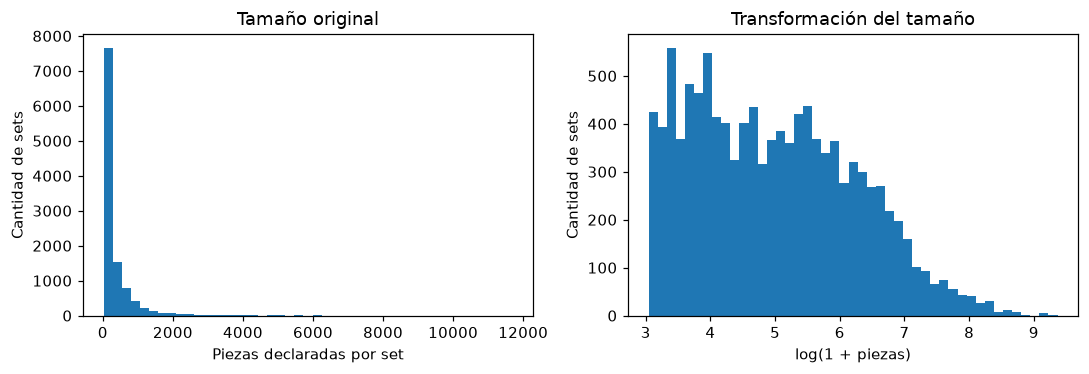

In [3]:
outliers=[]
for c in ['num_parts','inventory_quantity','n_colors','unique_part_ratio']:
    q1,q3=analytical[c].quantile([.25,.75]);iqr=q3-q1
    outliers.append(dict(variable=c,limite_inferior=q1-1.5*iqr,limite_superior=q3+1.5*iqr,
        cantidad=int(((analytical[c]<q1-1.5*iqr)|(analytical[c]>q3+1.5*iqr)).sum())))
display(pd.DataFrame(outliers));pd.DataFrame(outliers).to_csv(OUT/'atipicos_iqr.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(10,3.5))
axes[0].hist(analytical['num_parts'],bins=45);axes[0].set(xlabel='Piezas declaradas por set',ylabel='Cantidad de sets',title='Tamaño original')
axes[1].hist(np.log1p(analytical['num_parts']),bins=45);axes[1].set(xlabel='log(1 + piezas)',ylabel='Cantidad de sets',title='Transformación del tamaño')
savefig('distribucion')

## Preguntas de investigación

La mediana por año es descriptiva: cambios en la mezcla de temas pueden explicar parte de la variación. Para comparar temas usamos las seis familias más frecuentes. Los diagramas de dispersión relacionan dos variables y los boxplots muestran variación interna, no solo promedios. Se informa correlación de Spearman como asociación, sin interpretación causal.

Correlaciones de Spearman: {'size_colors': 0.7168214047851356, 'technic_unique_ratio': -0.18284148125330874}


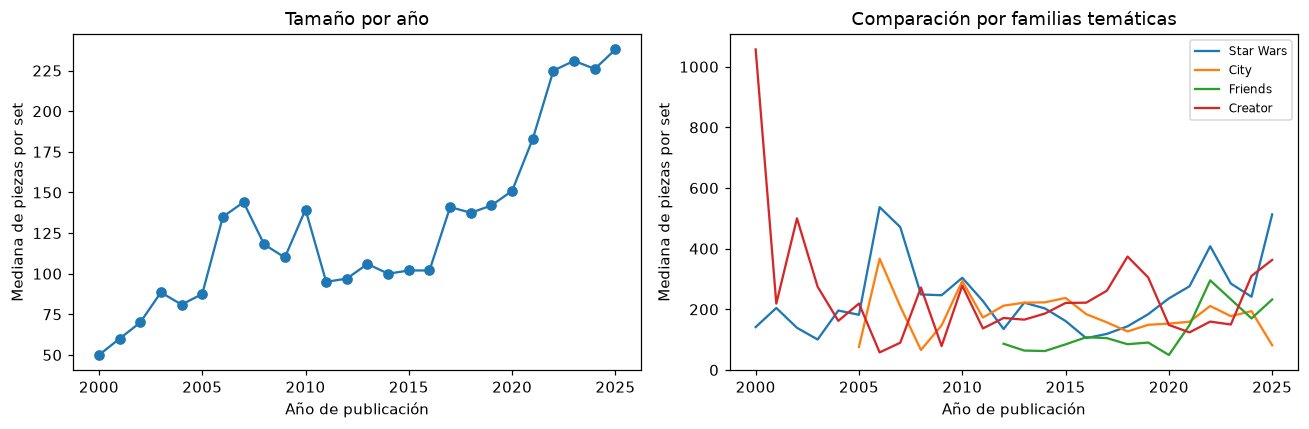

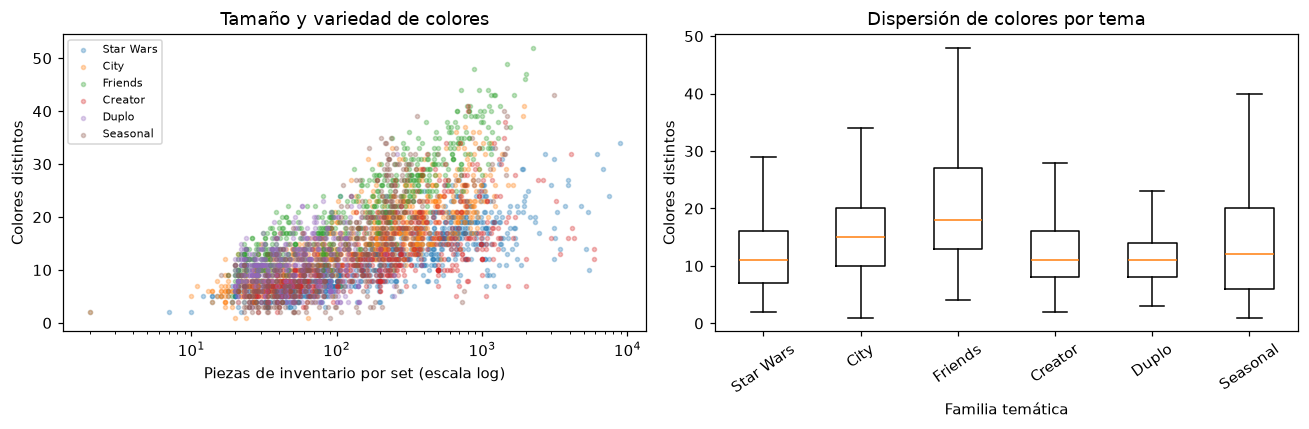

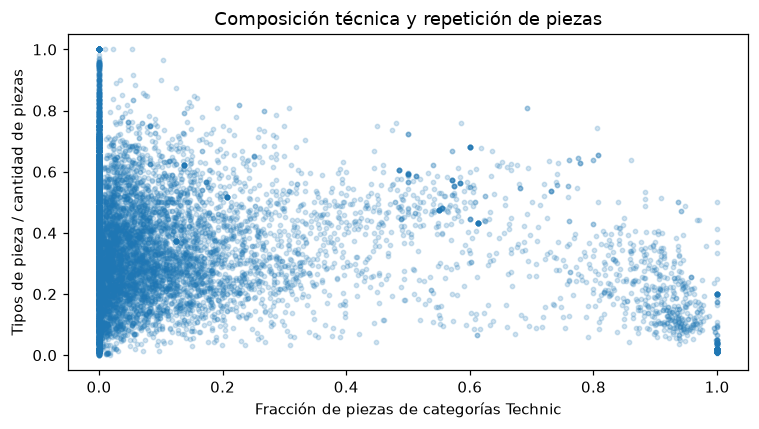

,sets,median_parts,median_colors
year,,,
2000,282,50.0,6.0
2001,257,60.0,7.0
2002,345,70.0,7.0
2003,312,88.5,8.0
2004,305,81.0,9.0
2005,260,87.5,9.0
2006,241,135.0,10.0
2007,229,144.0,11.0
2008,266,118.0,11.0


,sets,piezas,colores
theme_root,,,
Star Wars,845,208.0,11.0
City,779,178.0,15.0
Friends,591,103.0,18.0
Creator,552,208.5,11.0
Duplo,546,47.5,11.0
Seasonal,453,127.0,12.0
Educational and Dacta,448,100.0,7.0
Ninjago,436,183.0,14.0
LEGO Brand Store,346,50.0,7.0


In [4]:
top=analytical['theme_root'].value_counts().head(6).index.tolist()
annual=analytical.groupby('year').agg(sets=('set_num','size'),median_parts=('num_parts','median'),median_colors=('n_colors','median'))
annual.to_csv(OUT/'evolucion_anual.csv')
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].plot(annual.index,annual['median_parts'],marker='o');axes[0].set(xlabel='Año de publicación',ylabel='Mediana de piezas por set',title='Tamaño por año')
for theme in top[:4]:
    series=analytical.loc[analytical.theme_root.eq(theme)].groupby('year')['num_parts'].median()
    axes[1].plot(series.index,series,label=theme)
axes[1].set(xlabel='Año de publicación',ylabel='Mediana de piezas por set',title='Comparación por familias temáticas');axes[1].legend(fontsize=8)
savefig('pregunta1')
fig,axes=plt.subplots(1,2,figsize=(12,4))
for theme in top:
    s=analytical.loc[analytical.theme_root.eq(theme)]
    axes[0].scatter(s['inventory_quantity'],s['n_colors'],s=7,alpha=.3,label=theme)
axes[0].set_xscale('log');axes[0].set(xlabel='Piezas de inventario por set (escala log)',ylabel='Colores distintos',title='Tamaño y variedad de colores');axes[0].legend(fontsize=7)
axes[1].boxplot([analytical.loc[analytical.theme_root.eq(t),'n_colors'] for t in top],tick_labels=top,showfliers=False)
axes[1].tick_params(axis='x',rotation=35);axes[1].set(xlabel='Familia temática',ylabel='Colores distintos',title='Dispersión de colores por tema')
savefig('pregunta2')
fig,ax=plt.subplots(figsize=(7,4))
ax.scatter(analytical['technic_ratio'],analytical['unique_part_ratio'],s=8,alpha=.2)
ax.set(xlabel='Fracción de piezas de categorías Technic',ylabel='Tipos de pieza / cantidad de piezas',title='Composición técnica y repetición de piezas');savefig('pregunta3')
correlations=dict(size_colors=float(analytical[['inventory_quantity','n_colors']].corr(method='spearman').iloc[0,1]),
    technic_unique_ratio=float(analytical[['technic_ratio','unique_part_ratio']].corr(method='spearman').iloc[0,1]))
print('Correlaciones de Spearman:',correlations)
display(annual);display(analytical.groupby('theme_root').agg(sets=('set_num','size'),piezas=('num_parts','median'),colores=('n_colors','median')).sort_values('sets',ascending=False).head(10))

## Tendencia al agrupamiento y elección de k

Usamos cinco variables: log1p de piezas y colores, proporción de tipos únicos, de piezas transparentes y de piezas Technic. Excluimos año y nombre del tema: queremos perfiles de construcción, no imponer temas o épocas de antemano. StandardScaler evita que las unidades grandes dominen la distancia.

Implementamos la idea de Hopkins de la práctica: puntos uniformes en la caja de los datos, distancia al primer vecino para puntos sintéticos y al segundo para puntos reales (para excluirse a sí mismos). Con la convención H = suma(u)/(suma(u)+suma(w)), valores altos indican alejamiento de la uniformidad. Repetimos diez semillas y quitamos vectores idénticos solo para este diagnóstico. No es una prueba de que existan grupos verdaderos: asimetría y dependencias también elevan H.

Probamos k de 2 a 8 con KMeans, n_init=20. Seleccionamos el mayor Silhouette de una muestra fija de hasta 3000 sets y mostramos el codo. PCA solo se usa para representar en dos dimensiones; KMeans se ajusta en las cinco variables. Repetimos la solución con otra semilla para estudiar estabilidad.

Hopkins, 10 semillas: [0.9305795390749716, 0.9284785903375256, 0.928594521134869, 0.9279059979163585, 0.930132036417669, 0.9282395462994457, 0.9281210025894048, 0.9330521914551284, 0.9260551466929576, 0.9304521045847274]
k 2 Silhouette 0.3061828812594775
k 3 Silhouette 0.33824900893664006
k 4 Silhouette 0.3533360313365828
k 5 Silhouette 0.30619845924625033
k 6 Silhouette 0.2604280118134814
k 7 Silhouette 0.26533218047512674
k 8 Silhouette 0.27413163058556456
RESULTADOS {'quality': {'source_sets': 28492, 'eligible_sets': 11186, 'analytical_sets': 11158, 'no_valid_inventory': 28, 'excluded_inventory_rows': 2, 'duplicate_inventory_rows_removed': 0, 'join_missing': {'part_cat_id': 0, 'category': 0, 'color_name': 0, 'is_trans': 0}, 'mismatching_piece_counts': 5535}, 'correlations': {'size_colors': 0.7168214047851356, 'technic_unique_ratio': -0.18284148125330874}, 'selected_k': 4, 'silhouette': 0.3533360313365828, 'hopkins': [0.9305795390749716, 0.9284785903375256, 0.928594521134869, 0.92790

,k,inertia,silhouette
0,2,39594.340774,0.306183
1,3,30931.923551,0.338249
2,4,25422.711748,0.353336
3,5,21504.488989,0.306198
4,6,18889.437588,0.260428
5,7,16897.414444,0.265332
6,8,15456.953581,0.274132


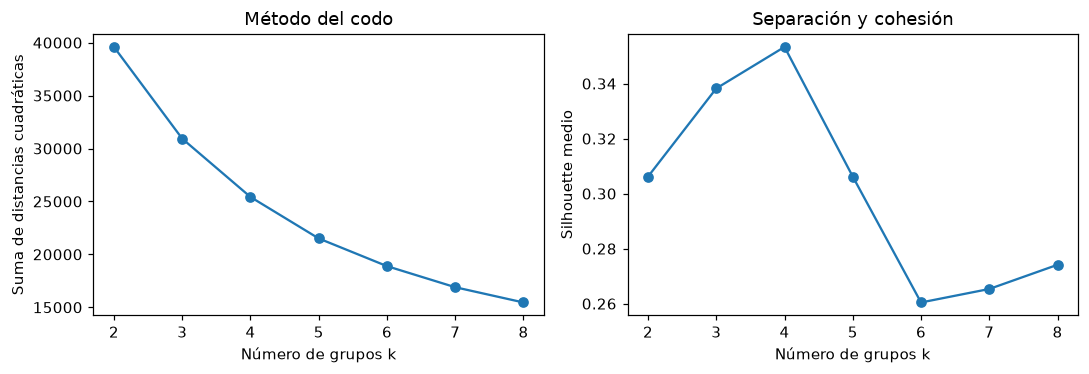

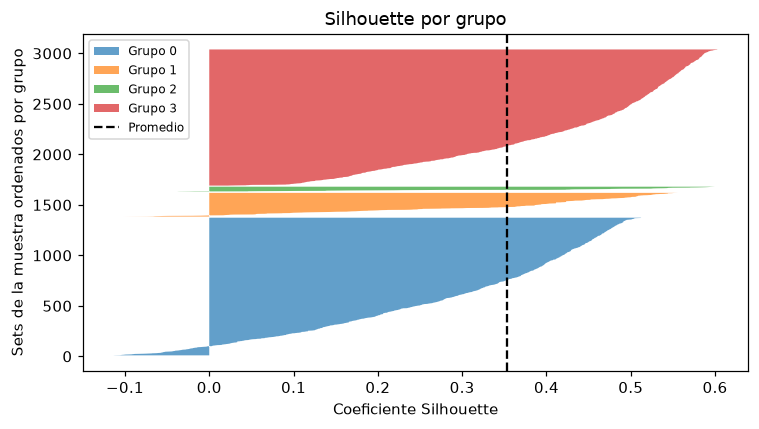

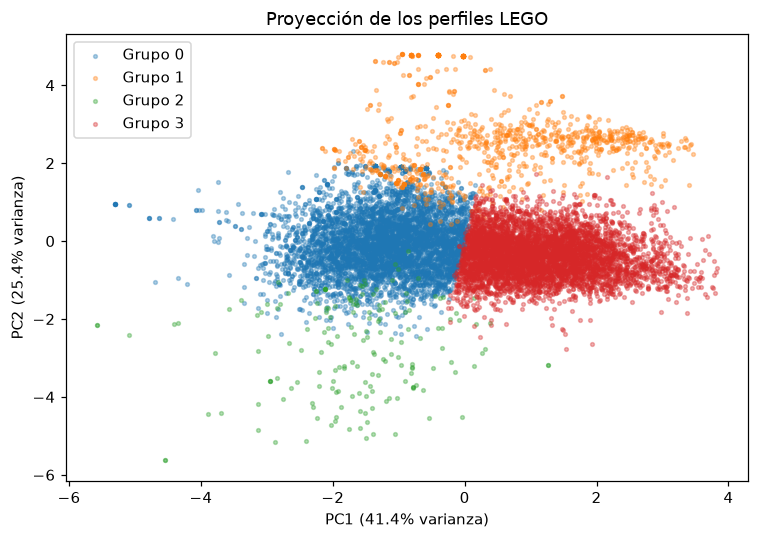

,sets,median_pieces,median_colors,median_unique_ratio,mean_transparent,mean_technic
cluster,,,,,,
0,5004,47.0,8.0,0.500000,0.056577,0.046200
1,930,140.0,9.0,0.232817,0.017447,0.811909
2,179,48.0,8.0,0.319444,0.568538,0.018032
3,5045,356.0,18.0,0.255556,0.048470,0.073289


In [5]:
features=pd.DataFrame({'log_pieces':np.log1p(analytical['inventory_quantity']),
    'log_colors':np.log1p(analytical['n_colors']),'unique_part_ratio':analytical['unique_part_ratio'],
    'transparent_ratio':analytical['transparent_ratio'],'technic_ratio':analytical['technic_ratio']},index=analytical.index)
assert not features.isna().any().any()
scaler=StandardScaler();z=scaler.fit_transform(features)
u=np.unique(z,axis=0);nn=NearestNeighbors(n_neighbors=2).fit(u);hopkins=[]
for seed in range(10):
    rng=np.random.default_rng(seed);real=u[rng.choice(len(u),size=min(500,len(u)),replace=False)]
    fake=rng.uniform(u.min(axis=0),u.max(axis=0),size=real.shape)
    ud=nn.kneighbors(fake,n_neighbors=1)[0][:,0];wd=nn.kneighbors(real,n_neighbors=2)[0][:,1]
    hopkins.append(float(ud.sum()/(ud.sum()+wd.sum())))
print('Hopkins, 10 semillas:',hopkins)
rng=np.random.default_rng(42);idx=rng.choice(len(z),size=min(3000,len(z)),replace=False)
search=[];fitted={}
for k in range(2,9):
    model=KMeans(n_clusters=k,n_init=20,random_state=42).fit(z)
    score=float(silhouette_score(z[idx],model.labels_[idx]))
    search.append(dict(k=k,inertia=float(model.inertia_),silhouette=score));fitted[k]=model
    print('k',k,'Silhouette',score,flush=True)
selection=pd.DataFrame(search);display(selection);selection.to_csv(OUT/'seleccion_k.csv',index=False)
k=int(selection.loc[selection.silhouette.idxmax(),'k']);model=fitted[k]
analytical['cluster']=model.labels_
stability=float(adjusted_rand_score(model.labels_,KMeans(n_clusters=k,n_init=20,random_state=2026).fit_predict(z)))
fig,axes=plt.subplots(1,2,figsize=(10,3.5))
axes[0].plot(selection.k,selection.inertia,marker='o');axes[0].set(xlabel='Número de grupos k',ylabel='Suma de distancias cuadráticas',title='Método del codo')
axes[1].plot(selection.k,selection.silhouette,marker='o');axes[1].set(xlabel='Número de grupos k',ylabel='Silhouette medio',title='Separación y cohesión');savefig('seleccion_k')
sil=silhouette_samples(z[idx],model.labels_[idx]);fig,ax=plt.subplots(figsize=(7,4));lower=10
for cluster in range(k):
    values=np.sort(sil[model.labels_[idx]==cluster]);upper=lower+len(values)
    ax.fill_betweenx(np.arange(lower,upper),0,values,alpha=.7,label=f'Grupo {cluster}')
    lower=upper+10
ax.axvline(sil.mean(),color='black',linestyle='--',label='Promedio');ax.set(xlabel='Coeficiente Silhouette',ylabel='Sets de la muestra ordenados por grupo',title='Silhouette por grupo');ax.legend(fontsize=8);savefig('silhouette')
pca=PCA(n_components=2,random_state=42);xy=pca.fit_transform(z)
fig,ax=plt.subplots(figsize=(7,5))
for cluster in range(k):
    keep=model.labels_==cluster;ax.scatter(xy[keep,0],xy[keep,1],s=6,alpha=.35,label=f'Grupo {cluster}')
ax.set(xlabel=f'PC1 ({pca.explained_variance_ratio_[0]:.1%} varianza)',ylabel=f'PC2 ({pca.explained_variance_ratio_[1]:.1%} varianza)',title='Proyección de los perfiles LEGO');ax.legend();savefig('clusters')
profiles=analytical.groupby('cluster').agg(sets=('set_num','size'),median_pieces=('inventory_quantity','median'),
    median_colors=('n_colors','median'),median_unique_ratio=('unique_part_ratio','median'),
    mean_transparent=('transparent_ratio','mean'),mean_technic=('technic_ratio','mean'))
display(profiles);profiles.to_csv(OUT/'perfiles.csv')
pd.crosstab(analytical['cluster'],analytical['theme_root'],normalize='index').to_csv(OUT/'temas_por_cluster.csv')
analytical.to_csv(ROOT/'datos/procesados/lego_sets_clusters.csv',index=False)
scaled=pd.DataFrame(z,columns=features.columns);scaled.insert(0,'set_num',analytical['set_num'].to_numpy());scaled.to_csv(ROOT/'datos/procesados/lego_features_escaladas.csv',index=False)
joblib.dump(dict(scaler=scaler,kmeans=model,pca_visualization=pca,feature_names=features.columns.tolist()),ROOT/'modelos/ej1_kmeans.joblib',compress=3)
result=dict(quality=quality,correlations=correlations,selected_k=k,silhouette=float(selection.loc[selection.k.eq(k),'silhouette'].iloc[0]),
    hopkins=hopkins,stability_ari=stability,pca_explained_variance=pca.explained_variance_ratio_.tolist(),
    profiles=profiles.reset_index().to_dict(orient='records'),years=[2000,2025],versions=dict(sklearn=sklearn.__version__,numpy=np.__version__,pandas=pd.__version__))
(OUT/'resultados.json').write_text(json.dumps(result,indent=2,ensure_ascii=False,allow_nan=False),encoding='utf-8')
print('RESULTADOS',result,flush=True)

## Conclusiones e interpretación

El dataset final contiene **11,158 sets**. Se excluyeron 28 sets elegibles por no contar con un inventario utilizable. En 5535 sets difieren las piezas declaradas y las calculadas desde las filas de piezas; no suponemos que representen exactamente la misma cobertura.

La mediana de piezas pasa de 50 en 2000 a 238 en 2025 dentro del recorte elegido. Esto es una comparación descriptiva, no una tendencia causal ni necesariamente monotónica. Los gráficos por tema ayudan a contextualizarla.

Tamaño y colores presentan correlación de Spearman **0.717**. La fracción Technic y la proporción de tipos únicos presentan correlación **-0.183**: el signo indica si una mayor presencia técnica se asocia con más o menos repetición, sin aislar tamaño o tema como posibles factores de confusión.

Se seleccionó **k=4** entre los valores probados, con Silhouette **0.353** en la muestra fija y ARI **0.997** entre dos semillas. Los grupos son perfiles relativos a nuestras cinco variables y transformaciones, no categorías objetivas del catálogo. Un Hopkins alto no basta por sí solo para justificar su calidad. El Silhouette positivo pero moderado y algunos valores negativos indican solapamiento y asignaciones ambiguas.

Como aplicación exploratoria, estos perfiles pueden ordenar sets por características constructivas. Para un recomendador real harían falta preferencias de usuarios y una evaluación específica. Con más tiempo estudiaríamos estabilidad al cambiar variables, otros recortes históricos y el efecto de valores extremos.

## Caracterización de los cuatro perfiles

- **Grupo 0**: 5004 sets pequeños y con mayor proporción de tipos únicos. Medianas de 47 piezas y 8 colores; proporción mediana de tipos únicos 50.0%. Fracciones medias Technic 4.6% y transparentes 5.7%.
- **Grupo 1**: 930 sets con predominio de piezas Technic. Medianas de 140 piezas y 9 colores; proporción mediana de tipos únicos 23.3%. Fracciones medias Technic 81.2% y transparentes 1.7%.
- **Grupo 2**: 179 sets con alta proporción de piezas transparentes. Medianas de 48 piezas y 8 colores; proporción mediana de tipos únicos 31.9%. Fracciones medias Technic 1.8% y transparentes 56.9%.
- **Grupo 3**: 5045 sets de mayor tamaño y variedad de colores. Medianas de 356 piezas y 18 colores; proporción mediana de tipos únicos 25.6%. Fracciones medias Technic 7.3% y transparentes 4.8%.

Los números de cluster son etiquetas arbitrarias. Las proporciones medias caracterizan sets, no una bolsa que mezcle todas las piezas de todos los sets.